# Graph Neural Networks from Scratch — Tutorial 10: GNNs for Scientific Machine Learning

### From a single prediction to a time-stepping surrogate: rollouts, stability, physics checks, and generalisation

*📺 Video on YouTube | 🐍 Python · NumPy · SciPy · PyTorch · PyTorch Geometric | Intermediate–Advanced*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

This is the **final tutorial** of the series.

In Tutorials 1–3, we learned how graphs are represented and built a **GCN** from scratch. In Tutorial 4, we moved to **PyTorch Geometric** and Cora. In Tutorials 5–7, we opened the layer into **message, aggregate, and update**, learned neighbour weights with **attention**, and studied **aggregators, sampling, and inductive learning**. In Tutorial 8, we added a **readout** for graph-level prediction. In Tutorial 9, we turned **meshes into graphs**, generated data with a **finite-element solver**, and trained a surrogate for steady heat conduction that we tested on **unseen meshes**.

Tutorial 9 ended with a list of open problems: the PDE residual was large, boundary conditions were only approximately learned, and the model only predicted a single steady state. Real engineering simulations are usually **time-dependent**, and many depend on **operating parameters**.

In this tutorial, we build a **time-stepping surrogate** — the approach used by MeshGraphNets and most learned simulators:

1. Simulate a **cooling plate** for many diffusivities $\alpha$ and many meshes.
2. Train a GNN to predict **one time step**: $\mathbf T^{n}\rightarrow\mathbf T^{n+1}$.
3. **Roll it out**: feed its own predictions back in for 25 steps — and watch errors accumulate.
4. Stabilise the rollout with **training noise**.
5. Check the physics: **exact boundary conditions**, the **heat balance**, and the **discrete PDE residual** — computed with message passing.
6. Test **interpolation vs. extrapolation** in $\alpha$, transfer to a **finer mesh**, and ask honestly whether the surrogate is **worth it** compared with the solver.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | PyG, real-world graph data, practical GCN implementation | ✅ |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | ✅ |
| 6 | Graph Attention Networks (GAT) | learned attention, neighbour weighting, multi-head attention | ✅ |
| 7 | GraphSAGE and Advanced Aggregation | aggregators, neighbour sampling, mini-batches, inductive learning | ✅ |
| 8 | Graph-Level Learning | readout, graph batching, graph classification and regression | ✅ |
| 9 | GNNs for Mesh-Based Systems | mesh → graph, edge features, FEM data, mesh generalisation | ✅ |
| **10** | **GNNs for Scientific Machine Learning** | **time-stepping surrogates, rollout stability, physics checks, generalisation** | **📍 You are here** |

The goal of the series was to progress from understanding graph representations and implementing GNNs from scratch to using practical tools for learning from complex connected systems, including computational meshes and physical systems. This tutorial completes that path.

---

In this tutorial, we will explore the essential components of a scientific GNN surrogate:

- What a surrogate is, and the difference between **one-shot** and **time-stepping** surrogates.
- A transient heat-conduction solver (implicit Euler + P1 finite elements), verified against an exact solution.
- **Operating parameters** as node features, and checking the **parameter coverage** of a dataset.
- **Residual learning** ($\Delta\mathbf T$) and **hard boundary conditions** built into the model.
- The FEM operator written as **message passing** — and verified against SciPy.
- **One-step training** vs. **multi-step rollout**, and why errors accumulate.
- **Noise injection** for stable rollouts.
- Physical checks: boundary values, **total heat** (an area-weighted readout from Tutorial 8), and the **PDE residual**.
- Interpolation vs. **extrapolation** in $\alpha$, transfer to a **finer mesh**, and a **cost comparison** with the solver.

We will begin by building the simulator. Then, we will train, roll out, stress-test, and critically evaluate the surrogate.

## The learning process

Our workflow in this tutorial will follow this sequence:

```text
     Transient FEM Solver (many α, many meshes)
                    |
                    v
      Trajectories  T⁰ → T¹ → … → T²⁵
                    |
                    v
     One-Step Pairs  (Tⁿ, α, mesh) → Tⁿ⁺¹
                    |
                    v
   Edge-Aware GNN: predicts ΔT, hard BC
                    |
                    v
         Train on One Step at a Time
                    |
                    v
   Rollout: feed predictions back in × 25
                    |
                    v
      Noise Injection → Stable Rollouts
                    |
                    v
   Physics Checks: BCs, heat balance, residual
                    |
                    v
   Interpolation vs. Extrapolation, Finer Mesh, Cost
```

The model is the edge-aware encode–process–decode network from Tutorial 9. What is new is **time**: the model is applied **repeatedly**, so its errors feed into its own inputs.

> **Is a good one-step model a good simulator?** Not necessarily. A model with 3% error per step can drift far from the truth after 25 steps. Evaluating surrogates by their **rollout**, not just their one-step loss, is one of the most important habits in learned simulation.
>
> This tutorial is deliberately honest about limitations. A surrogate that is fast but wrong, or accurate only inside its training range, can be worse than no surrogate. The aim is to learn how to **measure** trustworthiness, not to show that GNNs always win.

**Let's build a learned simulator, run it forward in time, and find out where it can and cannot be trusted.**

## 1. What is a scientific surrogate?

A numerical solver maps a problem description to a solution. A **surrogate** learns an approximation of that map from previously computed solutions:

$$
\mathcal S:\ (\mathcal G,\ \boldsymbol\mu)\ \longmapsto\ \mathbf u,\qquad \hat{\mathbf u}=\mathcal S_\theta(\mathcal G,\boldsymbol\mu)
$$

- $\mathcal G$ — geometry and mesh (our graph)
- $\boldsymbol\mu$ — operating parameters and boundary conditions
- $\mathbf u$ — the solution field

Two common designs:

| Design | Learns | Example |
|---|---|---|
| **One-shot** (Tutorial 9) | $(\mathcal G,\boldsymbol\mu)\mapsto\mathbf u$ directly | steady temperature from a heat source |
| **Time-stepping** (this tutorial) | $(\mathbf u^{n},\mathcal G,\boldsymbol\mu)\mapsto\mathbf u^{n+1}$, applied repeatedly | MeshGraphNets, learned weather and fluid models |

A time-stepping surrogate only has to learn a **local, short-time** update — which suits message passing well, because information only needs to travel a few hops per step (recall the receptive-field problem from Tutorial 9). The price is that errors **accumulate** over many steps.

| Target type | Examples |
|---|---|
| Field prediction | temperature, pressure, velocity, displacement |
| Global response | drag, pressure drop, total heat flow (Tutorial 8 readouts) |
| Time evolution | future states from current states |
| Inverse problems | infer parameters from observations |

## 2. Setup

We use the same environment as Tutorials 4–9. If PyG is missing, the cell below installs it.

In [1]:
import sys
import subprocess
import time
import copy

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)

try:
    import torch_geometric
except ImportError:
    print("PyTorch Geometric is not installed. Installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"])
    import torch_geometric
    print("Installation complete.")

import scipy
print("PyG:", torch_geometric.__version__)
print("SciPy:", scipy.__version__)

torch.manual_seed(7)
np.random.seed(7)

PyTorch: 2.11.0+cu130


/home/rohit/venvs/py13env/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyG: 2.8.1
SciPy: 1.17.1


In [2]:
# Configuration. On a CPU, each GNN takes about 5 minutes to train;
# on a GPU it is much faster. Reduce EPOCHS for a quick run.
EPOCHS = 40        # training epochs per model
NUM_LAYERS = 4      # message-passing layers
NOISE_STD = 0.01    # training-noise level for Part VI
DT, NUM_STEPS = 0.05, 25   # solver time step and trajectory length

# Part I — The physical system

## 3. A cooling plate

A square plate starts with a few hot spots. Its edges are held at $T=0$. Heat diffuses through the plate and leaves through the edges:

$$
\frac{\partial T}{\partial t}=\alpha\,\nabla^2T\quad\text{in }\Omega,\qquad T=0\ \text{on }\partial\Omega,\qquad T(\mathbf r,0)=T_0(\mathbf r)
$$

The **thermal diffusivity** $\alpha$ is our **operating parameter** — think of plates made of different materials. A larger $\alpha$ means faster cooling.

## 4. Discretisation: P1 finite elements + implicit Euler

We reuse the mesh and finite-element tools from Tutorial 9. In space, P1 elements give the stiffness matrix $\mathbf K$ and lumped mass $\mathbf M$. In time, the **implicit Euler** method gives one sparse linear solve per step:

$$
\left(\mathbf M+\Delta t\,\alpha\,\mathbf K\right)\mathbf T^{n+1}=\mathbf M\,\mathbf T^{n}
$$

Implicit Euler is unconditionally stable, so the solver never blows up, whatever $\alpha$ or $\Delta t$. Our learned surrogate will have no such guarantee.

The next cell collects the Tutorial 9 helper functions.

In [3]:
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from matplotlib.tri import Triangulation

def make_mesh(n, jitter=0.25, seed=0):
    """Irregular triangular mesh of the unit square (Tutorial 9)."""
    rng = np.random.default_rng(seed)
    grid = np.linspace(0.0, 1.0, n)
    X, Y = np.meshgrid(grid, grid)
    points = np.column_stack([X.ravel(), Y.ravel()])
    boundary = (np.isclose(points, 0.0) | np.isclose(points, 1.0)).any(axis=1)
    h = 1.0 / (n - 1)
    points[~boundary] += rng.uniform(-jitter * h, jitter * h, size=(int((~boundary).sum()), 2))
    return points, Triangulation(points[:, 0], points[:, 1]).triangles, boundary

def triangles_to_edge_index(triangles):
    """Unique mesh edges in both directions (Tutorial 9)."""
    pairs = np.concatenate([triangles[:, [0, 1]], triangles[:, [1, 2]], triangles[:, [2, 0]]])
    pairs = np.unique(np.sort(pairs, axis=1), axis=0)
    return np.concatenate([pairs, pairs[:, ::-1]]).T

def assemble_fem(points, triangles):
    """P1 stiffness matrix K and lumped mass vector m (Tutorial 9)."""
    p = points[triangles]
    x, y = p[..., 0], p[..., 1]
    b = np.stack([y[:, 1] - y[:, 2], y[:, 2] - y[:, 0], y[:, 0] - y[:, 1]], axis=1)
    c = np.stack([x[:, 2] - x[:, 1], x[:, 0] - x[:, 2], x[:, 1] - x[:, 0]], axis=1)
    area = 0.5 * np.abs(b[:, 0] * c[:, 1] - b[:, 1] * c[:, 0])
    K_local = (b[:, :, None] * b[:, None, :] + c[:, :, None] * c[:, None, :]) / (4 * area[:, None, None])
    K = sp.csr_matrix((K_local.ravel(), (np.repeat(triangles, 3, axis=1).ravel(), np.tile(triangles, 3).ravel())),
                      shape=(len(points), len(points)))
    m = np.zeros(len(points))
    np.add.at(m, triangles.ravel(), np.repeat(area / 3, 3))
    return K, m

## 5. The transient solver

`simulate()` runs one complete trajectory and returns everything the surrogate will need: the mesh, the FEM operator, the parameter $\alpha$, and the temperature at all $26$ time levels.

Because $\mathbf M+\Delta t\,\alpha\,\mathbf K$ does not change over time, we factorise it once (`splu`) and reuse the factorisation at every step.

In [4]:
def hot_spots(points, rng):
    """Initial condition: one to three Gaussian hot spots."""
    T = np.zeros(len(points))
    for _ in range(rng.integers(1, 4)):
        centre = rng.uniform(0.2, 0.8, size=2)
        width = rng.uniform(0.05, 0.15)
        T += rng.uniform(0.5, 1.0) * np.exp(-((points - centre) ** 2).sum(axis=1) / (2 * width**2))
    return T

def simulate(n, seed, alpha, T0=None):
    rng = np.random.default_rng(seed)
    points, triangles, boundary = make_mesh(n, seed=seed)
    K, m = assemble_fem(points, triangles)
    interior = ~boundary

    lu = spla.splu((sp.diags(m) + DT * alpha * K)[interior][:, interior].tocsc())
    T = hot_spots(points, rng) if T0 is None else T0(points)
    T[boundary] = 0.0
    history = [T]
    for _ in range(NUM_STEPS):
        T_next = np.zeros_like(T)
        T_next[interior] = lu.solve((m * T)[interior])
        T = T_next
        history.append(T)

    return dict(points=points, triangles=triangles, boundary=boundary, K=K, m=m,
                alpha=alpha, n=n, T=np.stack(history))

## 6. Verify the solver

For the initial condition $T_0=\sin(\pi x)\sin(\pi y)$, the exact solution decays as a single mode:

$$
T(\mathbf r,t)=e^{-2\pi^2\alpha t}\,\sin(\pi x)\sin(\pi y)
$$

We compare the decay of the peak temperature with this formula.

Peak temperature after t = 1.25: FEM = 0.4836, exact = 0.4770, relative difference = 1.39%


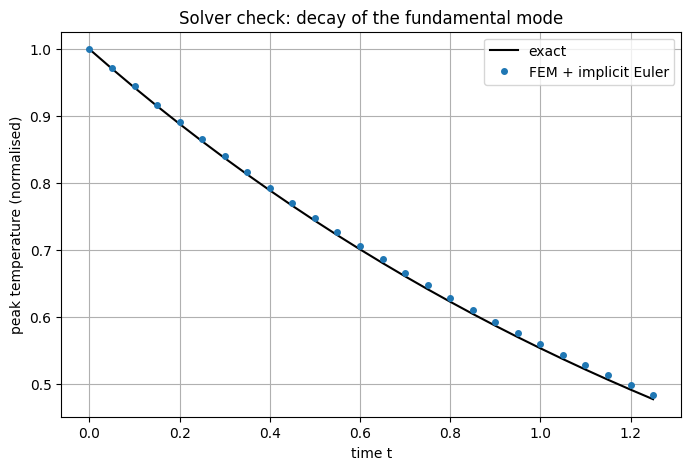

In [5]:
alpha_check = 0.03
tr = simulate(24, seed=1, alpha=alpha_check, T0=lambda p: np.sin(np.pi * p[:, 0]) * np.sin(np.pi * p[:, 1]))
times = DT * np.arange(NUM_STEPS + 1)
peak_fem = tr["T"].max(axis=1) / tr["T"][0].max()
peak_exact = np.exp(-2 * np.pi**2 * alpha_check * times)

print(f"Peak temperature after t = {times[-1]:.2f}: FEM = {peak_fem[-1]:.4f}, exact = {peak_exact[-1]:.4f}, "
      f"relative difference = {abs(peak_fem[-1] - peak_exact[-1]) / peak_exact[-1]:.2%}")

plt.figure(figsize=(8, 5))
plt.plot(times, peak_exact, "k-", label="exact")
plt.plot(times, peak_fem, "o", markersize=4, label="FEM + implicit Euler")
plt.xlabel("time t")
plt.ylabel("peak temperature (normalised)")
plt.title("Solver check: decay of the fundamental mode")
plt.legend()
plt.grid(True)
plt.show()

The small remaining difference comes from the spatial mesh and the first-order time stepping. For our purposes, the solver is accurate enough to act as the "ground truth" — in practice, this role is played by OpenFOAM or another validated code.

## 7. One trajectory

Let's simulate one plate and look at the temperature at a few time levels.

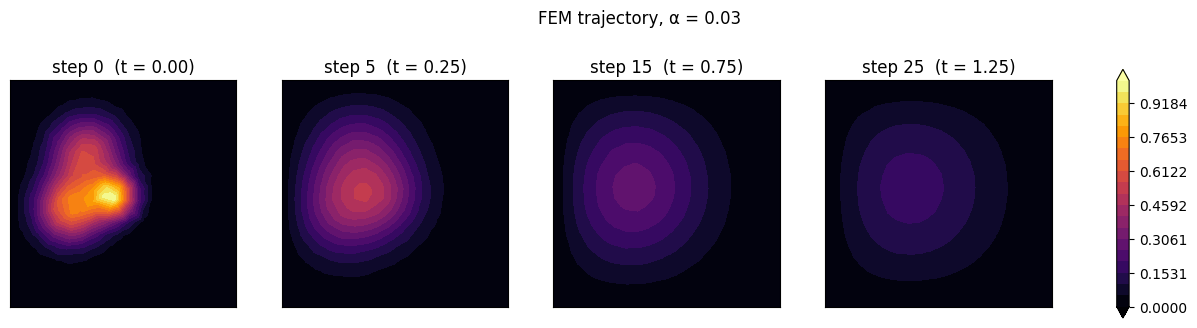

In [6]:
def plot_snapshots(tr, steps, fields=None, title=""):
    fields = tr["T"] if fields is None else fields
    pts, tri = tr["points"], tr["triangles"]
    fig, axes = plt.subplots(1, len(steps), figsize=(4.2 * len(steps), 3.8))
    vmax = tr["T"][0].max()
    for ax, k in zip(axes, steps):
        cf = ax.tricontourf(pts[:, 0], pts[:, 1], tri, fields[k], levels=np.linspace(0, vmax, 21),
                            cmap="inferno", extend="both")
        ax.set_title(f"step {k}  (t = {k * DT:.2f})")
        ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(cf, ax=axes, shrink=0.85)
    fig.suptitle(title)
    plt.show()

demo_tr = simulate(20, seed=3, alpha=0.03)
plot_snapshots(demo_tr, [0, 5, 15, 25], title=f"FEM trajectory, α = {demo_tr['alpha']}")

## 8. Datasets: many plates, many meshes, many diffusivities

Each trajectory has its **own mesh** (as in Tutorial 9), its **own initial hot spots**, and its **own diffusivity** $\alpha$. We split **by trajectory**:

| Split | Meshes $n$ | $\alpha$ range | Purpose |
|---|---|---|---|
| Train | 12, 16, 20 | $[0.01,\ 0.04]$ | learn the update |
| Validation | 12, 16, 20 | $[0.01,\ 0.04]$ | choose the checkpoint |
| Test — interpolation | 12, 16, 20 | $[0.01,\ 0.04]$ | new plates, familiar $\alpha$ |
| **Test — extrapolation** | 12, 16, 20 | $[0.05,\ 0.06]$ | **faster cooling than ever seen** |
| **Test — finer mesh** | **28** | $[0.01,\ 0.04]$ | **unseen resolution** |

In [7]:
def make_split(resolutions, per_resolution, alpha_range, seed_offset):
    trajs = []
    for n in resolutions:
        alphas = np.random.default_rng(seed_offset + n).uniform(*alpha_range, size=per_resolution)
        trajs += [simulate(n, seed_offset + 100 * n + i, a) for i, a in enumerate(alphas)]
    return trajs

start = time.time()
train_trajs  = make_split((12, 16, 20), 15, (0.01, 0.04), seed_offset=1000)
val_trajs    = make_split((12, 16, 20), 3,  (0.01, 0.04), seed_offset=20000)
test_trajs   = make_split((12, 16, 20), 4,  (0.01, 0.04), seed_offset=30000)
extrap_trajs = make_split((12, 16, 20), 4,  (0.05, 0.06), seed_offset=40000)
fine_trajs   = make_split((28,), 6,         (0.01, 0.04), seed_offset=50000)

print(f"Simulated {sum(map(len, [train_trajs, val_trajs, test_trajs, extrap_trajs, fine_trajs]))} "
      f"trajectories in {time.time() - start:.1f} s")
for name, s in [("Train", train_trajs), ("Validation", val_trajs), ("Test (interp.)", test_trajs),
                ("Test (extrap.)", extrap_trajs), ("Test (n = 28)", fine_trajs)]:
    print(f"{name:15s}: {len(s):2d} trajectories")

Simulated 84 trajectories in 0.5 s
Train          : 45 trajectories
Validation     :  9 trajectories
Test (interp.) : 12 trajectories
Test (extrap.) : 12 trajectories
Test (n = 28)  :  6 trajectories


## 9. Check the parameter coverage

A surrogate can only be expected to work where it has seen data. Always plot the parameters of every split before training.

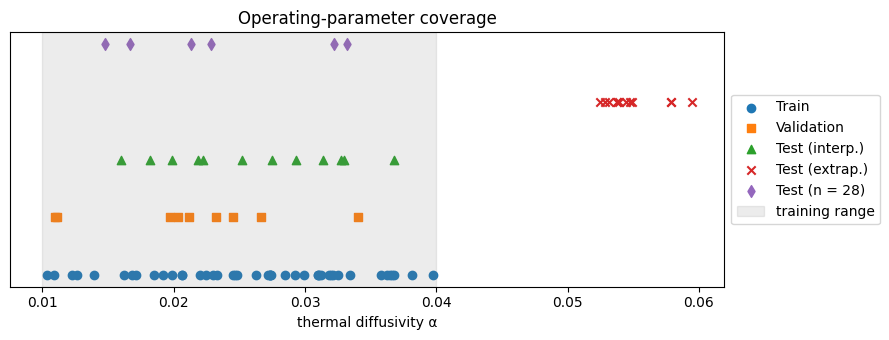

In [8]:
plt.figure(figsize=(9, 3.5))
for i, (name, s, marker) in enumerate([("Train", train_trajs, "o"), ("Validation", val_trajs, "s"),
                                        ("Test (interp.)", test_trajs, "^"), ("Test (extrap.)", extrap_trajs, "x"),
                                        ("Test (n = 28)", fine_trajs, "d")]):
    plt.scatter([t["alpha"] for t in s], [i] * len(s), marker=marker, label=name)
plt.axvspan(0.01, 0.04, color="gray", alpha=0.15, label="training range")
plt.yticks([])
plt.xlabel("thermal diffusivity α")
plt.title("Operating-parameter coverage")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 🧪 Hands-on Exercise 1

1. Simulate the same initial condition with $\alpha=0.01$ and $\alpha=0.06$ and compare the snapshots at step 25.
2. Estimate how far heat diffuses in one time step: $\ell\approx\sqrt{\alpha\,\Delta t}$. Compare $\ell$ with the mesh spacing $h=1/(n-1)$ for $n=12$ and $n=28$. How many hops does one step need to "see"?

In [9]:
# TODO: compare diffusivities and estimate the per-step diffusion length.

# for alpha in [0.01, 0.06]:
#     tr = simulate(20, seed=3, alpha=alpha)
#     plot_snapshots(tr, [0, 25], title=f"alpha = {alpha}")
# print(np.sqrt(0.04 * DT), 1 / 11, 1 / 27)

# Part II — From trajectories to graphs

## 10. What does the model see?

For each time step $n$ of each trajectory, we build one graph:

**Node features:**
$$
\mathbf x_i=\left[\,T_i^{n},\ b_i,\ \tilde\alpha\,\right],\qquad \tilde\alpha=20\,\alpha
$$

- $T_i^n$ — current temperature
- $b_i$ — boundary flag
- $\tilde\alpha$ — the **operating parameter**, broadcast to every node and scaled to order one

We deliberately **leave out the coordinates**. The physics does not depend on absolute position, only on relative geometry — which the edge features provide. This makes the model **translation-invariant**, as in Tutorial 8's rod networks.

**Edge features** (Tutorial 9): $\mathbf e_{ji}=10\cdot[\Delta x,\ \Delta y,\ d]$.

**Target:** $T_i^{n+1}$.

We also store the FEM operator on the graph — the off-diagonal entries of $\mathbf K$ as an **edge weight** `k_edge`, its diagonal `k_diag` and the lumped mass `m` as **node attributes**. The model does not use them; we need them for the physics checks in Part VII.

In [9]:
from torch_geometric.data import Data

ALPHA_SCALE, EDGE_SCALE = 20.0, 10.0

def trajectory_to_graph(tr):
    """Static part of the graph for one trajectory (mesh, geometry, FEM operator)."""
    ei = triangles_to_edge_index(tr["triangles"])
    rel = tr["points"][ei[0]] - tr["points"][ei[1]]                 # r_j - r_i for edge j -> i
    K = tr["K"].tocsr()
    n_nodes = len(tr["points"])
    return Data(
        edge_index=torch.tensor(ei, dtype=torch.long),
        edge_attr=torch.tensor(EDGE_SCALE * np.column_stack([rel, np.linalg.norm(rel, axis=1)]), dtype=torch.float),
        boundary=torch.tensor(tr["boundary"]),
        alpha=torch.full((n_nodes, 1), tr["alpha"], dtype=torch.float),
        k_edge=torch.tensor(np.asarray(K[ei[1], ei[0]]).ravel(), dtype=torch.float),   # K_ij for edge j -> i
        k_diag=torch.tensor(K.diagonal(), dtype=torch.float).view(-1, 1),
        m=torch.tensor(tr["m"], dtype=torch.float).view(-1, 1),
        pos=torch.tensor(tr["points"], dtype=torch.float),
    )

def step_graph(static, T_now, T_next=None):
    """One training example: current temperature in, next temperature out."""
    d = static.clone()
    T_now = torch.as_tensor(T_now, dtype=torch.float).view(-1, 1)
    d.x = torch.cat([T_now, d.boundary.float().view(-1, 1), ALPHA_SCALE * d.alpha], dim=1)
    if T_next is not None:
        d.y = torch.as_tensor(T_next, dtype=torch.float).view(-1, 1)
    return d

static_demo = trajectory_to_graph(demo_tr)
g = step_graph(static_demo, demo_tr["T"][0], demo_tr["T"][1])
print(g)
print("Node features [T, boundary, 20·α] of the first 3 nodes:\n", g.x[:3])

Data(edge_index=[2, 2242], edge_attr=[2242, 3], pos=[400, 2], boundary=[400], alpha=[400, 1], k_edge=[2242], k_diag=[400, 1], m=[400, 1], x=[400, 3], y=[400, 1])
Node features [T, boundary, 20·α] of the first 3 nodes:
 tensor([[0.0000, 1.0000, 0.6000],
        [0.0000, 1.0000, 0.6000],
        [0.0000, 1.0000, 0.6000]])


## 11. The FEM operator is message passing

In Tutorial 9, Exercise 2, we saw that $\mathbf K$ has non-zeros exactly on the mesh edges. That means $\mathbf K\mathbf T$ is a **message-passing operation** with fixed weights:

$$
(\mathbf K\mathbf T)_i=\underbrace{K_{ii}\,T_i}_{\text{self term}}+\sum_{j\in\mathcal N(i)}\underbrace{K_{ij}\,T_j}_{\text{message from }j}
$$

```text
message:   K_ij · T_j          (edge weight × source value)
aggregate: sum over neighbours
update:    + K_ii · T_i
```

We implement it with PyG's `scatter` — so it works on **batches** of meshes, exactly like a GNN layer — and verify it against SciPy.

In [10]:
from torch_geometric.utils import scatter

def apply_K(d, T):
    """Compute K @ T with message passing. Works on a single graph or a batch."""
    src, dst = d.edge_index
    messages = d.k_edge.view(-1, 1) * T[src]
    return d.k_diag * T + scatter(messages, dst, dim=0, dim_size=T.size(0), reduce="sum")

T_test = torch.tensor(demo_tr["T"][3], dtype=torch.float).view(-1, 1)
KT_scipy = demo_tr["K"] @ demo_tr["T"][3]
KT_mp = apply_K(static_demo, T_test).squeeze(-1).numpy()
print("Max difference between K@T (SciPy) and message passing:", np.abs(KT_scipy - KT_mp).max())

Max difference between K@T (SciPy) and message passing: 2.805632022262472e-07


A finite-element operator is a GNN layer whose weights come from geometry instead of training. A learned GNN generalises this: its "weights" depend on the features and are learned from data.

## 12. Build the training pairs

Every trajectory gives 25 pairs $(\mathbf T^n,\mathbf T^{n+1})$. The validation set uses one-step pairs too, so model selection is cheap; we evaluate **rollouts** separately in Part V.

In [11]:
from torch_geometric.loader import DataLoader

def pairs(trajs):
    out = []
    for tr in trajs:
        static = trajectory_to_graph(tr)
        out += [step_graph(static, tr["T"][k], tr["T"][k + 1]) for k in range(NUM_STEPS)]
    return out

train_pairs = pairs(train_trajs)
val_pairs = pairs(val_trajs)
train_loader = DataLoader(train_pairs, batch_size=32, shuffle=True)
val_loader = DataLoader(val_pairs, batch_size=64)

DT_STD = torch.cat([d.y - d.x[:, :1] for d in train_pairs]).std().item()
print("Training pairs:", len(train_pairs), "| validation pairs:", len(val_pairs))
print(f"Typical temperature change per step (std of ΔT): {DT_STD:.4f}")

Training pairs: 1125 | validation pairs: 225
Typical temperature change per step (std of ΔT): 0.0088


# Part III — The surrogate model

## 13. Two design choices that matter

**1. Residual learning.** The temperature changes only slightly in one step (compare the std of $\Delta T$ above with temperatures of order 1). Predicting $\mathbf T^{n+1}$ directly would force the network to copy $\mathbf T^n$ almost exactly. Instead, it predicts the **change**:

$$
\hat{\mathbf T}^{n+1}=\mathbf T^{n}+\sigma_{\Delta T}\cdot\operatorname{GNN}(\mathbf T^n,\ \mathcal G,\ \alpha)
$$

where $\sigma_{\Delta T}$ is the standard deviation of $\Delta T$ on the training set, so the network output is of order one.

**2. Hard boundary conditions.** In Tutorial 9, boundary values were only approximately zero. Here we multiply by $(1-b_i)$, so the boundary condition is satisfied **exactly, by construction**:

$$
\hat T_i^{n+1}\leftarrow(1-b_i)\,\hat T_i^{n+1}
$$

## 14. The model

The processor layer is the edge-aware layer from Tutorial 9, with SiLU activations (smooth activations often work better for physical fields).

In [12]:
from torch_geometric.nn import MessagePassing

class EdgeAwareLayer(MessagePassing):
    """Tutorial 9 layer: message from [h_i, h_j, e_ji], mean aggregation, residual update."""
    def __init__(self, hidden_dim, edge_dim):
        super().__init__(aggr="mean")
        self.message_mlp = nn.Sequential(nn.Linear(2 * hidden_dim + edge_dim, hidden_dim), nn.SiLU(),
                                         nn.Linear(hidden_dim, hidden_dim), nn.SiLU())
        self.update_mlp = nn.Sequential(nn.Linear(2 * hidden_dim, hidden_dim), nn.SiLU(),
                                        nn.Linear(hidden_dim, hidden_dim))

    def forward(self, h, edge_index, edge_attr):
        m = self.propagate(edge_index, h=h, edge_attr=edge_attr)
        return h + self.update_mlp(torch.cat([h, m], dim=-1))

    def message(self, h_i, h_j, edge_attr):
        return self.message_mlp(torch.cat([h_i, h_j, edge_attr], dim=-1))


class StepSurrogate(nn.Module):
    """Predicts T^{n+1} from T^n: residual learning + hard boundary condition."""
    def __init__(self, hidden_dim=64, num_layers=4):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(3, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, hidden_dim))
        self.processor = nn.ModuleList([EdgeAwareLayer(hidden_dim, 3) for _ in range(num_layers)])
        self.decoder = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, 1))

    def forward(self, d):
        h = self.encoder(d.x)
        for layer in self.processor:
            h = layer(h, d.edge_index, d.edge_attr)
        T_now, interior = d.x[:, :1], 1 - d.x[:, 1:2]
        return (T_now + DT_STD * self.decoder(h)) * interior


class StepMLP(nn.Module):
    """Baseline: same inputs and output structure, no connectivity."""
    def __init__(self, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, hidden_dim), nn.SiLU(),
                                 nn.Linear(hidden_dim, 1))

    def forward(self, d):
        return (d.x[:, :1] + DT_STD * self.net(d.x)) * (1 - d.x[:, 1:2])


class Persistence(nn.Module):
    """Trivial baseline: tomorrow equals today."""
    def forward(self, d):
        return d.x[:, :1] * (1 - d.x[:, 1:2])

We also keep two baselines:

| Model | Uses neighbours? | Learns? |
|---|---|---|
| **Persistence** — $\hat{\mathbf T}^{n+1}=\mathbf T^n$ | ❌ | ❌ |
| **MLP** — same inputs, node by node | ❌ | ✅ |
| **GNN surrogate** | ✅ | ✅ |

Persistence is the "do nothing" baseline. Any surrogate must beat it, or it has learned nothing about the dynamics.

## 15. Create the model and run a forward pass

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = StepSurrogate(num_layers=NUM_LAYERS).to(device)
print(model.processor[0])
print("Processor layers:", NUM_LAYERS)
print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

batch = next(iter(train_loader)).to(device)
with torch.no_grad():
    out = model(batch)
print("\nPrediction shape:", tuple(out.shape), "| target shape:", tuple(batch.y.shape))
print("Max |prediction| on boundary nodes:", out[batch.x[:, 1] == 1].abs().max().item())

EdgeAwareLayer()
Processor layers: 4
Device: cpu
Trainable parameters: 108737

Prediction shape: (8176, 1) | target shape: (8176, 1)
Max |prediction| on boundary nodes: 0.0


The boundary prediction is **exactly zero**, even for an untrained model — the hard constraint at work.

## 16. Evaluation function: one-step error

For training and model selection, we measure the one-step error in units of the typical change $\sigma_{\Delta T}$:

$$
\text{one-step error}=\frac{\text{MSE}(\hat{\mathbf T}^{n+1},\mathbf T^{n+1})}{\sigma_{\Delta T}^2}
$$

A value near 1 means "as wrong as a typical step is large"; persistence scores about 0.7 here. Values far below that mean the model has learned the update.

In [14]:
@torch.no_grad()
def one_step_error(model, loader):
    model.eval()
    total, count = 0.0, 0
    for b in loader:
        b = b.to(device)
        total += F.mse_loss(model(b), b.y, reduction="sum").item()
        count += b.y.numel()
    return total / count / DT_STD**2

print(f"Persistence one-step error:     {one_step_error(Persistence(), val_loader):.3f}")
print(f"Untrained GNN one-step error:   {one_step_error(model, val_loader):.3f}")

Persistence one-step error:     0.680
Untrained GNN one-step error:   0.691


# Part IV — Train on one step at a time

## 17. Training loop

The loop is the one from Tutorial 9: mini-batches of graphs, best-validation checkpointing, and a cosine learning-rate schedule. The loss is the one-step error from Section 16.

The `noise_std` argument is used in Part VI; for now it is zero.

In [ ]:
def fit(model, epochs=EPOCHS, lr=1e-3, noise_std=0.0, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = {"train": [], "val": []}
    best_val, best_state = float("inf"), None

    for epoch in range(1, epochs + 1):
        model.train()
        total, count = 0.0, 0
        for b in train_loader:
            b = b.to(device)
            if noise_std > 0:                                    # Part VI: corrupt the input temperature
                interior = 1 - b.x[:, 1:2]
                noise = noise_std * torch.randn_like(interior) * interior
                b.x = torch.cat([b.x[:, :1] + noise, b.x[:, 1:]], dim=1)
            optimizer.zero_grad()
            loss = F.mse_loss(model(b), b.y) / DT_STD**2
            loss.backward()
            optimizer.step()
            total += loss.item() * b.num_graphs
            count += b.num_graphs
        scheduler.step()

        val = one_step_error(model, val_loader)
        history["train"].append(total / count)
        history["val"].append(val)
        if val < best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"Epoch {epoch:03d} | train one-step error {history['train'][-1]:.4f} | val {val:.4f}")

    model.load_state_dict(best_state)
    return history

torch.manual_seed(7)
start = time.time()
model = StepSurrogate(num_layers=NUM_LAYERS).to(device)
history = fit(model)
print(f"\nTraining time: {time.time() - start:.0f} s | best validation one-step error: {min(history['val']):.4f}")

Epoch 001 | train one-step error 0.7858 | val 0.2578


## 18. Plot the learning curves

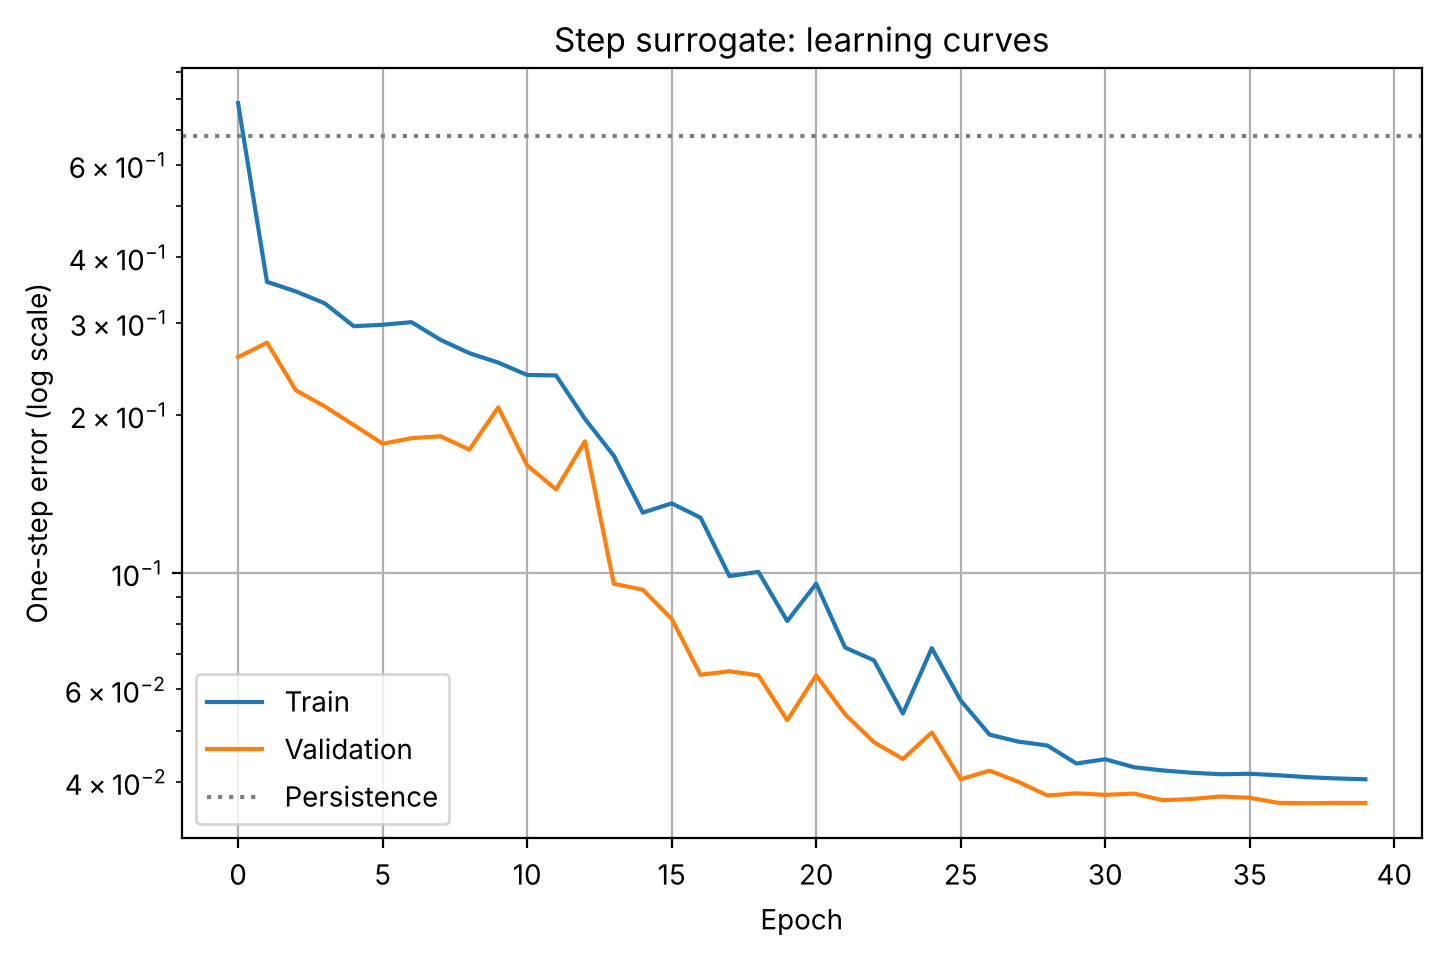

In [17]:
plt.figure(figsize=(8, 5))
plt.semilogy(history["train"], label="Train")
plt.semilogy(history["val"], label="Validation")
plt.axhline(one_step_error(Persistence(), val_loader), color="gray", linestyle=":", label="Persistence")
plt.xlabel("Epoch")
plt.ylabel("One-step error (log scale)")
plt.title("Step surrogate: learning curves")
plt.legend()
plt.grid(True)
plt.show()

The one-step error falls far below persistence. By this measure, the surrogate looks excellent. The next part shows why that is not enough.

We also train the MLP baseline with the same loop (it takes only seconds).

In [18]:
torch.manual_seed(7)
mlp = StepMLP().to(device)
fit(mlp, verbose=False)
print(f"One-step validation error | persistence {one_step_error(Persistence(), val_loader):.3f} "
      f"| MLP {one_step_error(mlp, val_loader):.3f} | GNN {one_step_error(model, val_loader):.4f}")

One-step validation error | persistence 0.680 | MLP 0.228 | GNN 0.0364


# Part V — Rollout: running the surrogate as a simulator

## 19. Feeding predictions back in

In use, the surrogate does not receive the true $\mathbf T^n$ at every step — only the initial condition. It must use **its own** previous prediction:

```text
true T⁰ ──▶ model ──▶ T̂¹ ──▶ model ──▶ T̂² ──▶ model ──▶ … ──▶ T̂²⁵
```

Every small error becomes part of the next input. And those inputs are slightly **unlike anything seen in training** — a distribution shift that can make the next error larger still.

In [19]:
@torch.no_grad()
def rollout(model, tr):
    """Run the surrogate for NUM_STEPS from the true initial condition."""
    model.eval()
    static = trajectory_to_graph(tr)
    T = torch.tensor(tr["T"][0], dtype=torch.float)
    preds = [T.numpy()]
    for _ in range(NUM_STEPS):
        T = model(step_graph(static, T).to(device)).squeeze(-1).cpu()
        preds.append(T.numpy())
    return np.stack(preds)

def rollout_errors(model, trajs):
    """Mean relative L2 error at every step over a set of trajectories."""
    errs = []
    for tr in trajs:
        pred = rollout(model, tr)
        errs.append(np.linalg.norm(pred[1:] - tr["T"][1:], axis=1) / np.linalg.norm(tr["T"][1:], axis=1))
    return np.mean(errs, axis=0)

roll = {name: rollout_errors(m, test_trajs) for name, m in
        [("Persistence", Persistence()), ("MLP", mlp), ("GNN", model)]}

for name, e in roll.items():
    print(f"{name:12s} | relative error after 1 step: {e[0]:.3f} | after 25 steps: {e[-1]:.3f}")

Persistence  | relative error after 1 step: 0.127 | after 25 steps: 2.288
MLP          | relative error after 1 step: 0.078 | after 25 steps: 0.560
GNN          | relative error after 1 step: 0.026 | after 25 steps: 0.161


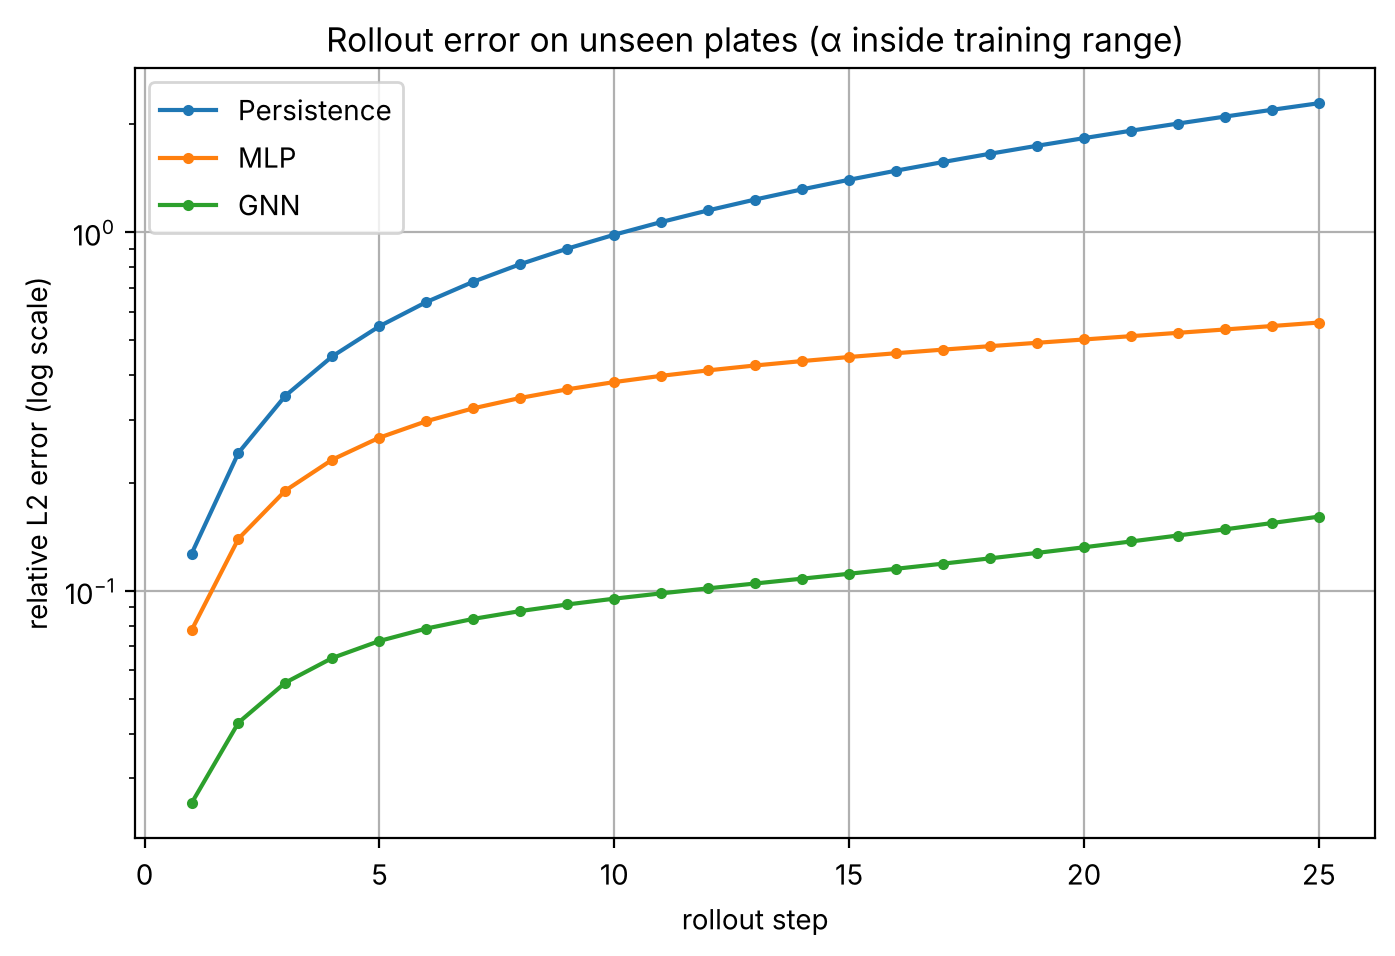

In [20]:
steps = np.arange(1, NUM_STEPS + 1)
plt.figure(figsize=(8, 5))
for name, e in roll.items():
    plt.plot(steps, e, marker="o", markersize=3, label=name)
plt.yscale("log")
plt.xlabel("rollout step")
plt.ylabel("relative L2 error (log scale)")
plt.title("Rollout error on unseen plates (α inside training range)")
plt.legend()
plt.grid(True)
plt.show()

Three observations:

1. **Persistence** is wrong from the start and gets worse quickly — the plate cools, persistence does not.
2. The **MLP** cannot see neighbours, so it cannot compute diffusion; it can only learn a rough average cooling rate per node.
3. The **GNN** is far better at step 1 — but its error still **grows** with every step.

This growth is the central challenge of learned simulators. Note also that the relative error naturally rises as the plate cools, because $\lVert\mathbf T\rVert$ itself shrinks.

## 20. Visualise a rollout

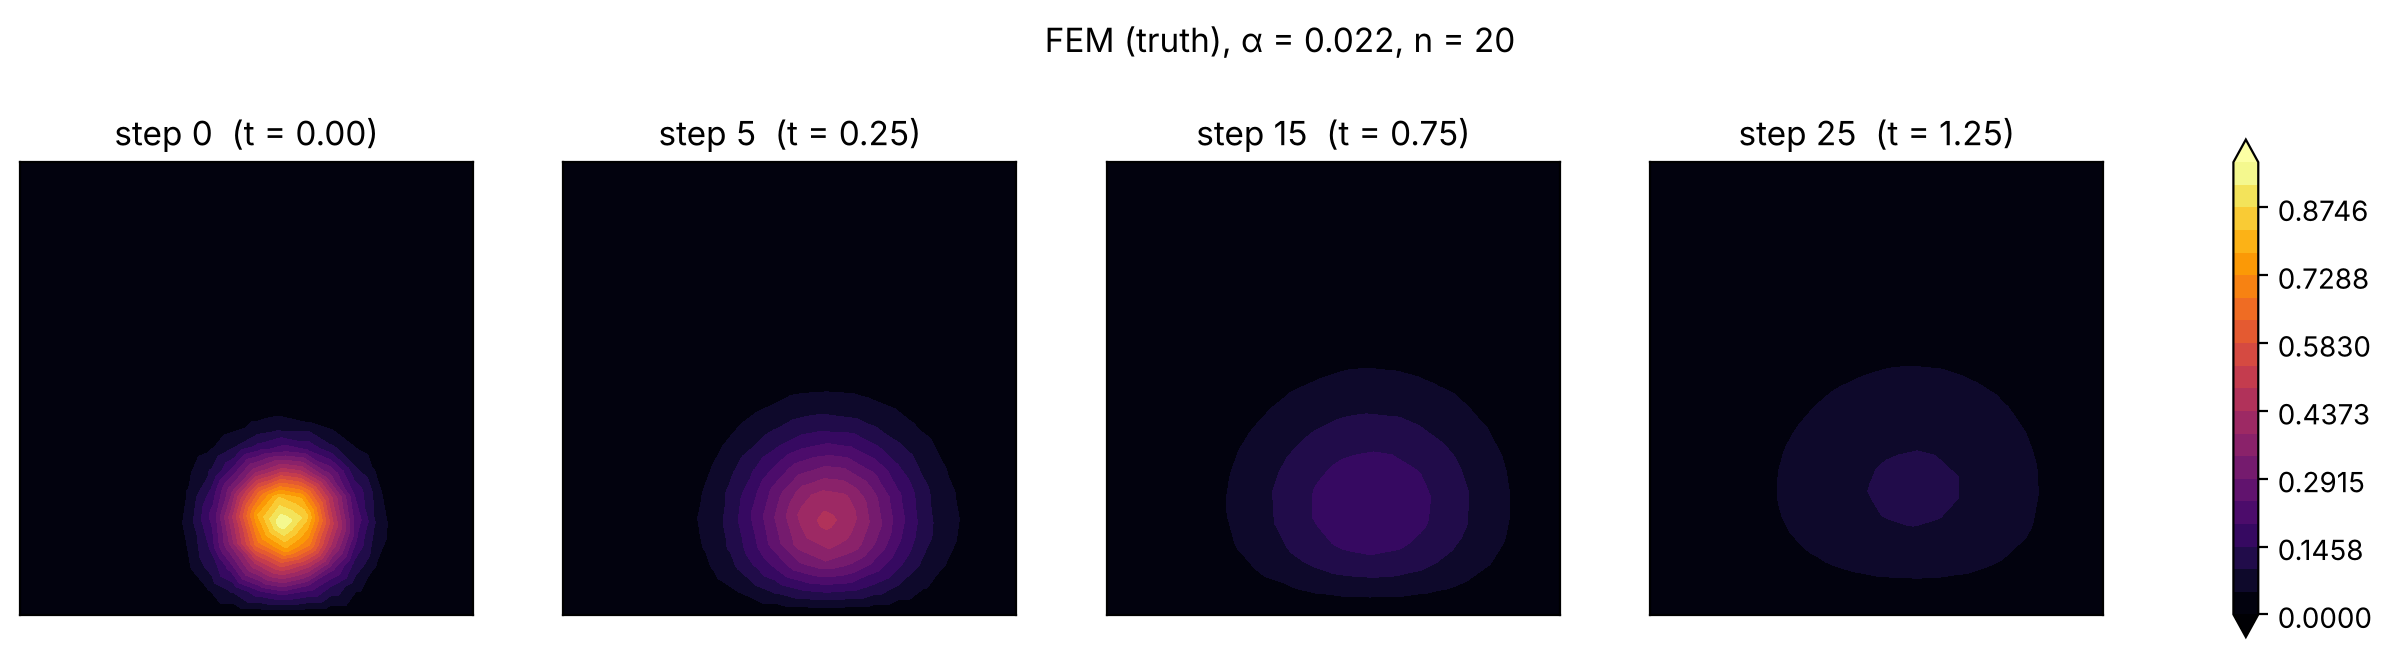

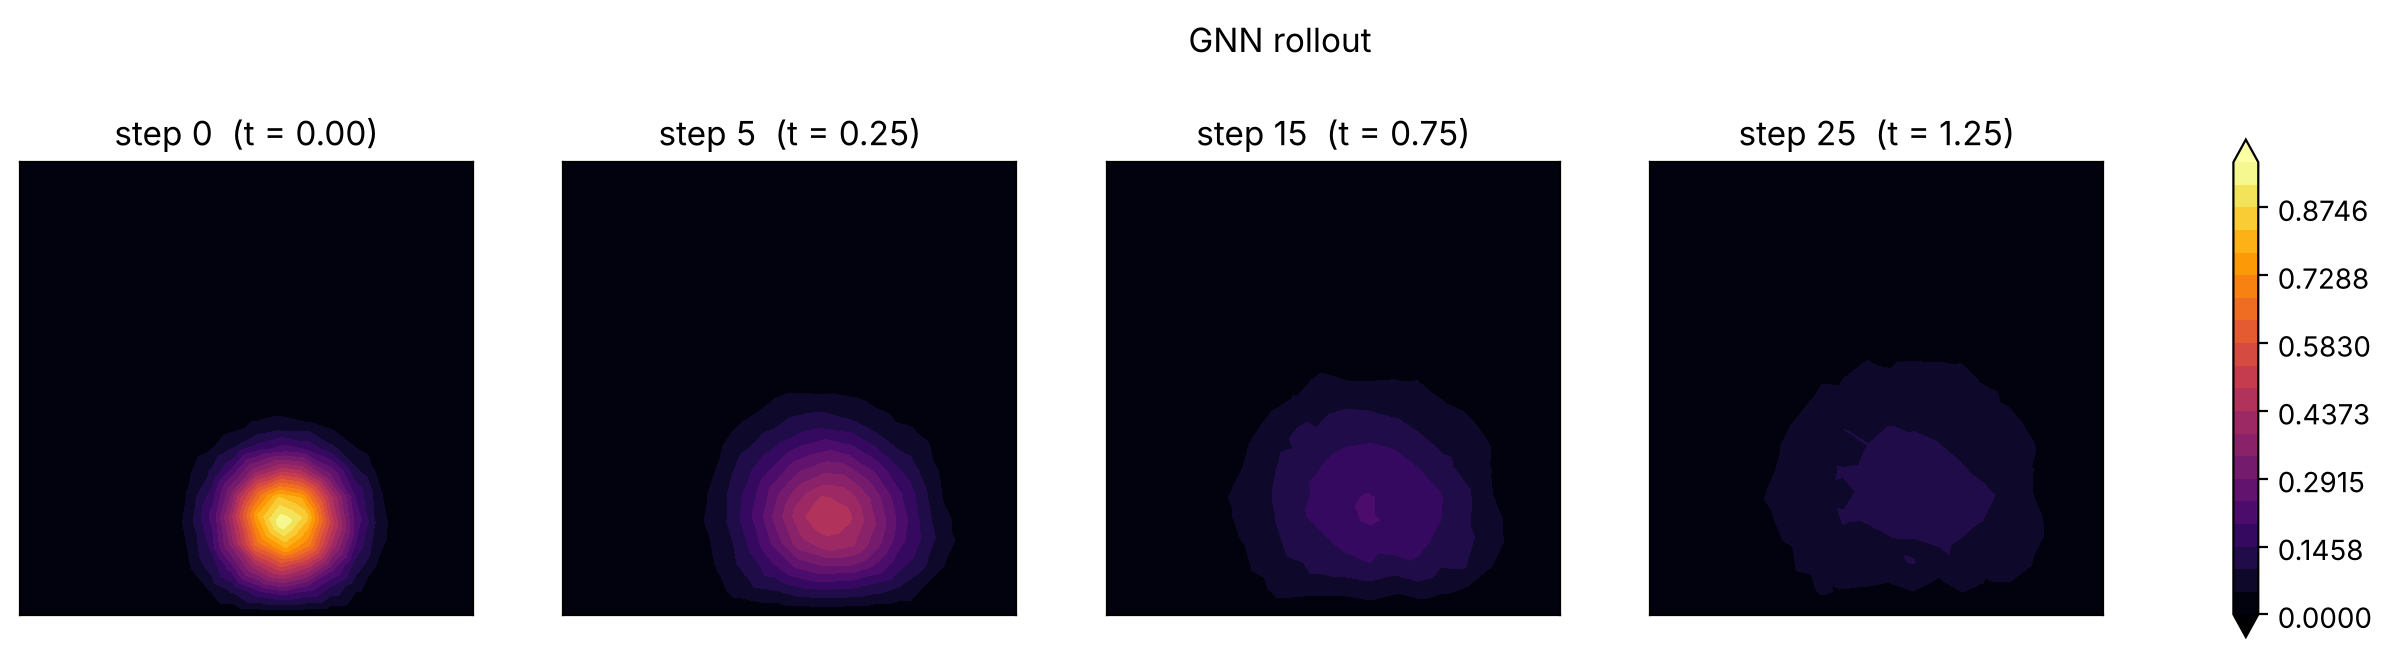

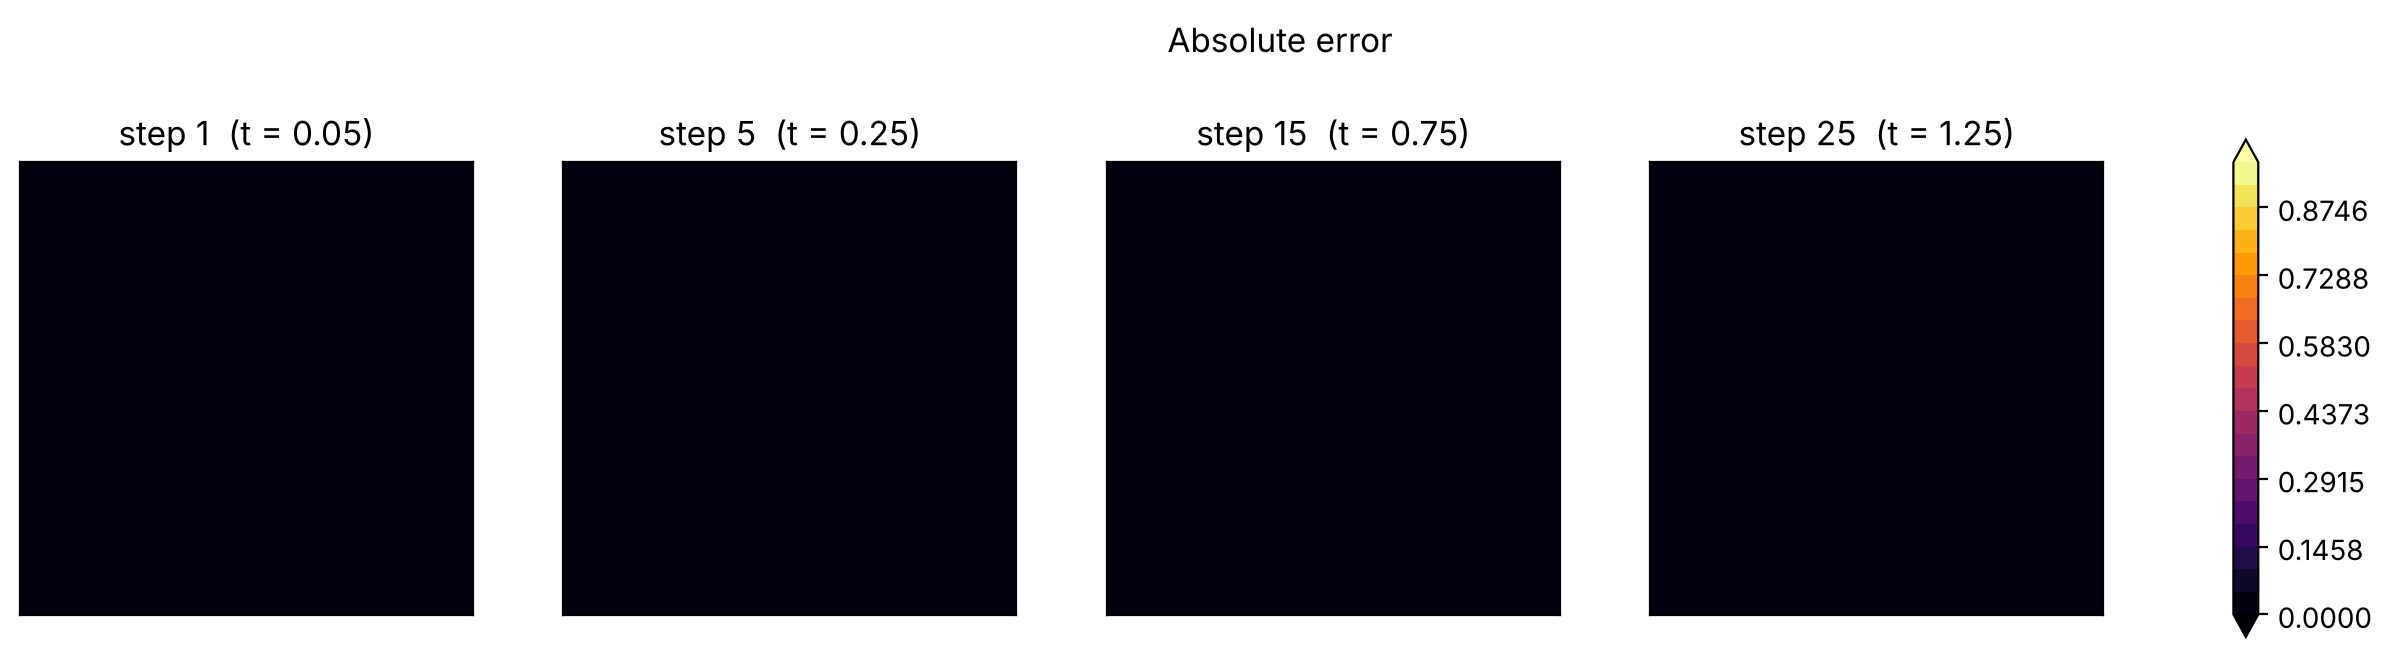

In [21]:
tr = test_trajs[-1]
pred = rollout(model, tr)
plot_snapshots(tr, [0, 5, 15, 25], title=f"FEM (truth), α = {tr['alpha']:.3f}, n = {tr['n']}")
plot_snapshots(tr, [0, 5, 15, 25], fields=pred, title="GNN rollout")
plot_snapshots(tr, [1, 5, 15, 25], fields=np.abs(pred - tr["T"]), title="Absolute error")

# Part VI — Training noise for stable rollouts

## 21. The idea

During training, the model always receives **perfect** inputs. During rollout, it receives its **own slightly wrong** outputs. It has never learned how to handle them.

A simple fix, used in MeshGraphNets and "Learning to Simulate": **add small random noise to the input temperature during training**, but keep the **clean** target. The model learns to map a slightly perturbed state back towards the correct next state — it learns to **correct** errors instead of propagating them.

$$
\mathbf T^{n}_{\text{input}}=\mathbf T^{n}+\boldsymbol\varepsilon,\qquad \boldsymbol\varepsilon\sim\mathcal N(0,\ \sigma_{\text{noise}}^2),\qquad \text{target}=\mathbf T^{n+1}
$$

The noise is applied to interior nodes only, so the boundary flag and boundary values stay consistent. We use $\sigma_{\text{noise}}=$ `NOISE_STD`, comparable to the typical change per step.

In [22]:
torch.manual_seed(7)
start = time.time()
model_noise = StepSurrogate(num_layers=NUM_LAYERS).to(device)
history_noise = fit(model_noise, noise_std=NOISE_STD, verbose=False)
print(f"Training time: {time.time() - start:.0f} s")

roll["GNN + noise"] = rollout_errors(model_noise, test_trajs)
print(f"One-step validation error | GNN {one_step_error(model, val_loader):.4f} "
      f"| GNN + noise {one_step_error(model_noise, val_loader):.4f}")
for name in ["GNN", "GNN + noise"]:
    print(f"{name:12s} | after 1 step: {roll[name][0]:.3f} | after 25 steps: {roll[name][-1]:.3f} "
          f"| mean over rollout: {roll[name].mean():.3f}")

Training time: 320 s


One-step validation error | GNN 0.0364 | GNN + noise 0.1197
GNN          | after 1 step: 0.026 | after 25 steps: 0.161 | mean over rollout: 0.103
GNN + noise  | after 1 step: 0.028 | after 25 steps: 0.145 | mean over rollout: 0.084


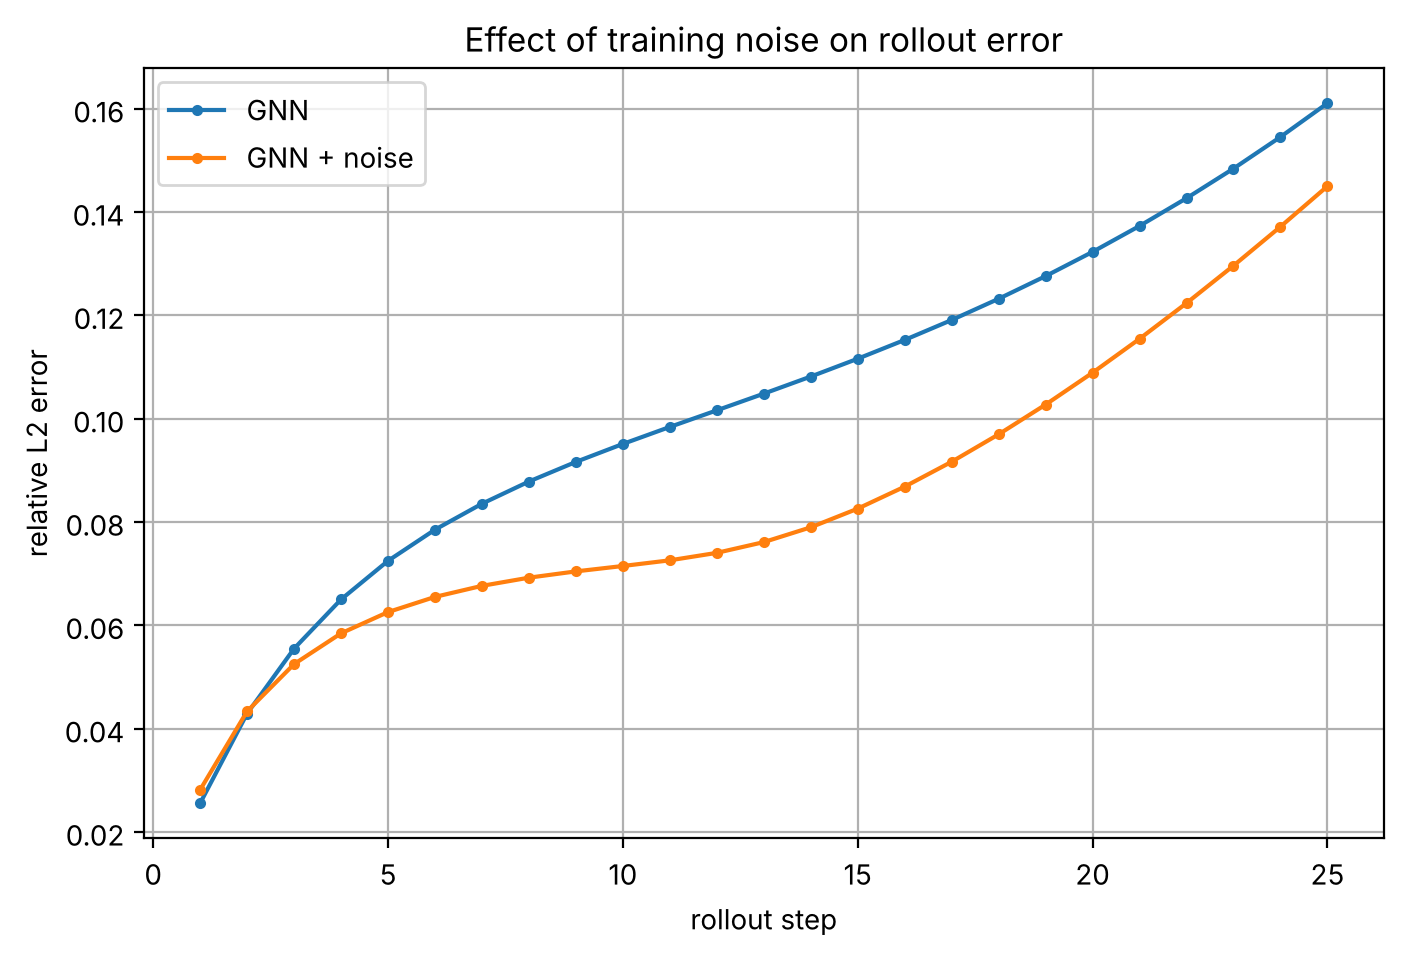

In [23]:
plt.figure(figsize=(8, 5))
for name in ["GNN", "GNN + noise"]:
    plt.plot(steps, roll[name], marker="o", markersize=3, label=name)
plt.xlabel("rollout step")
plt.ylabel("relative L2 error")
plt.title("Effect of training noise on rollout error")
plt.legend()
plt.grid(True)
plt.show()

Look closely at the first printed line: on the **one-step** validation metric, the noise-trained model looks about **three times worse** — it was trained on corrupted inputs, so it is slightly less precise on perfect ones. Yet its error **grows more slowly** during the rollout, and over 25 steps it is the better simulator. Had we selected models by one-step loss alone, we would have picked the wrong one. The difference becomes dramatic in Part VIII.

> **Lesson:** select and report surrogates by **rollout** performance, the way they will actually be used.

# Part VII — Physical checks

## 22. Boundary conditions

With the hard constraint, boundary values should be exactly zero at every step of every rollout.

In [24]:
worst = max(np.abs(rollout(model_noise, tr)[:, tr["boundary"]]).max() for tr in test_trajs)
print("Max |T| on boundary nodes over all test rollouts:", worst)

Max |T| on boundary nodes over all test rollouts: 0.0


Exactly zero — compare this with the small but non-zero boundary errors in Tutorial 9. **Enforce what you know exactly.**

## 23. Heat balance: an area-weighted readout

The total heat in the plate is

$$
Q(t)=\int_\Omega T\,dA\ \approx\ \sum_i m_i\,T_i
$$

This is the **area-weighted sum readout** from Tutorial 8: a graph-level quantity, independent of mesh resolution. Physically, $Q$ can only **decrease** (heat leaves through the cold edges, and there are no sources). Does the surrogate respect this?

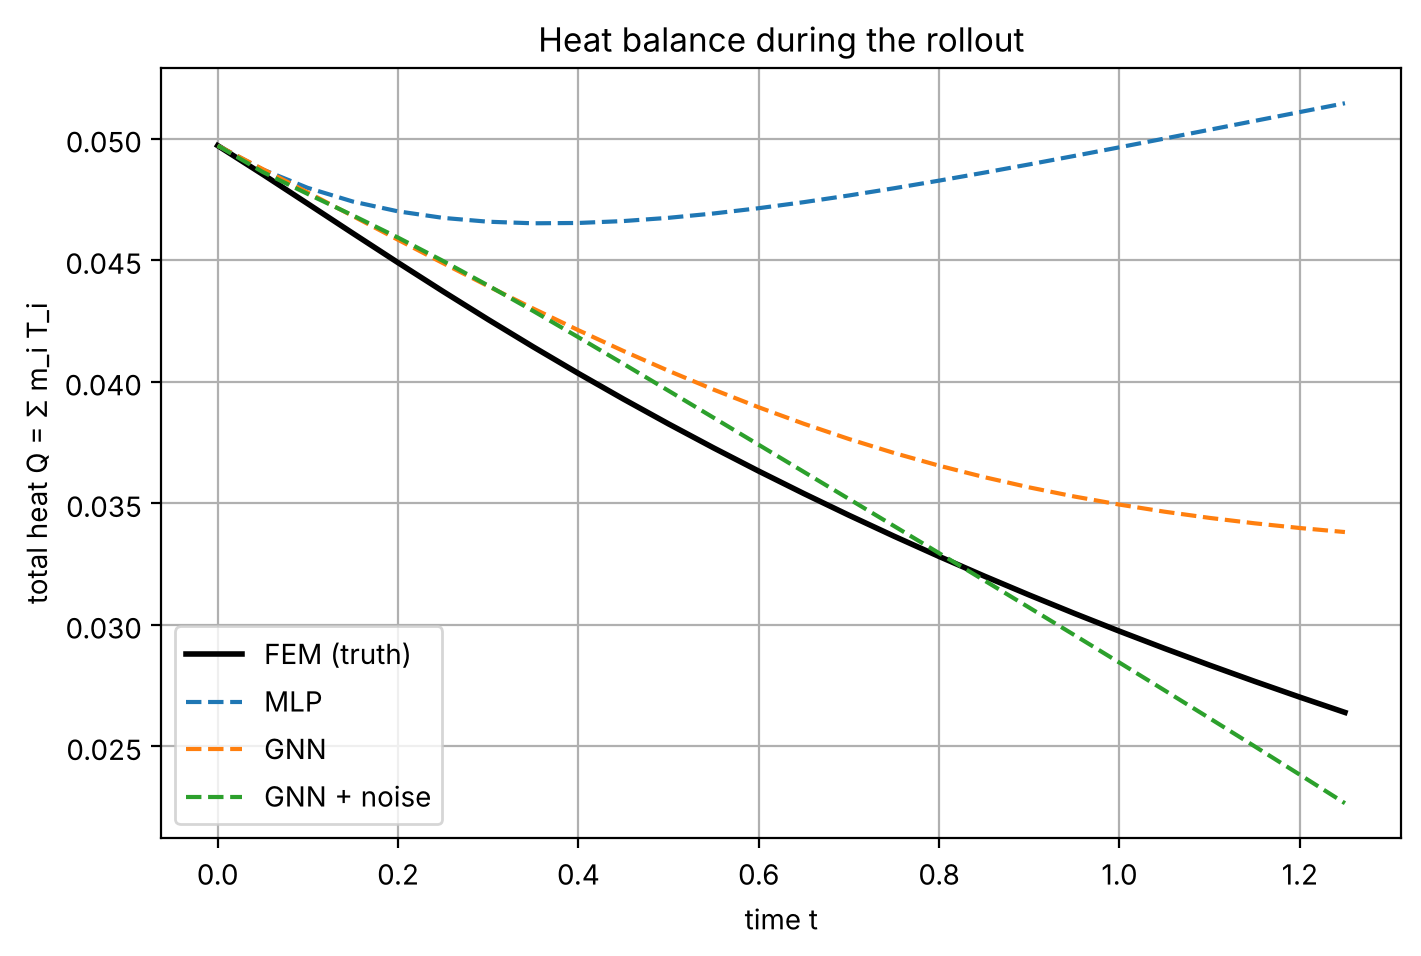

MLP          | relative error in final total heat: 0.343 | steps where Q increased: 60


GNN          | relative error in final total heat: 0.086 | steps where Q increased: 0


GNN + noise  | relative error in final total heat: 0.112 | steps where Q increased: 10


In [25]:
tr = test_trajs[-1]
Q_true = tr["T"] @ tr["m"]
Q_pred = {name: rollout(m, tr) @ tr["m"] for name, m in [("MLP", mlp), ("GNN", model), ("GNN + noise", model_noise)]}

plt.figure(figsize=(8, 5))
plt.plot(times, Q_true, "k-", linewidth=2, label="FEM (truth)")
for name, Q in Q_pred.items():
    plt.plot(times, Q, "--", label=name)
plt.xlabel("time t")
plt.ylabel("total heat Q = Σ m_i T_i")
plt.title("Heat balance during the rollout")
plt.legend()
plt.grid(True)
plt.show()

def heat_errors(model, trajs):
    final, increases = [], 0
    for tr in trajs:
        Q = rollout(model, tr) @ tr["m"]
        Qt = tr["T"] @ tr["m"]
        final.append(abs(Q[-1] - Qt[-1]) / Qt[-1])
        increases += int((np.diff(Q) > 1e-6).sum())
    return np.mean(final), increases

for name, m in [("MLP", mlp), ("GNN", model), ("GNN + noise", model_noise)]:
    err, inc = heat_errors(m, test_trajs)
    print(f"{name:12s} | relative error in final total heat: {err:.3f} | steps where Q increased: {inc}")

A physically meaningful **global** quantity is a strong, cheap check. The models only learned to match temperatures node by node; nothing tells them that total heat must decrease. Any step where $Q$ increases is a physical violation, even if the field error is small.

## 24. The PDE residual

Each true step satisfies the implicit-Euler equation at interior nodes exactly:

$$
\mathbf r=\mathbf M\left(\mathbf T^{n+1}-\mathbf T^n\right)+\Delta t\,\alpha\,\mathbf K\,\mathbf T^{n+1}=\mathbf 0
$$

For a predicted step, $\mathbf r\neq\mathbf 0$. We compute it with our message-passing `apply_K` from Section 11 — on whole batches at once — and report it relative to the size of the update $\lVert\mathbf M(\mathbf T^{n+1}-\mathbf T^n)\rVert$.

In [26]:
def pde_residual(d, T_next):
    """Implicit-Euler residual at interior nodes, via message passing."""
    T_now = d.x[:, :1]
    r = d.m * (T_next - T_now) + DT * d.alpha * apply_K(d, T_next)
    return r * (1 - d.x[:, 1:2])

test_loader = DataLoader(pairs(test_trajs), batch_size=64)

@torch.no_grad()
def relative_residual(model, loader):
    num, den = 0.0, 0.0
    for b in loader:
        b = b.to(device)
        num += pde_residual(b, model(b)).pow(2).sum().item()
        den += (b.m * (b.y - b.x[:, :1]) * (1 - b.x[:, 1:2])).pow(2).sum().item()
    return (num / den) ** 0.5

class Truth(nn.Module):
    def forward(self, d):
        return d.y

for name, m in [("FEM (truth)", Truth()), ("Persistence", Persistence()), ("MLP", mlp),
                ("GNN", model), ("GNN + noise", model_noise)]:
    print(f"{name:12s} | relative one-step PDE residual: {relative_residual(m, test_loader):.3f}")

FEM (truth)  | relative one-step PDE residual: 0.000
Persistence  | relative one-step PDE residual: 1.229
MLP          | relative one-step PDE residual: 0.713


GNN          | relative one-step PDE residual: 0.358


GNN + noise  | relative one-step PDE residual: 0.595


The truth has zero residual, as it must; persistence, which ignores diffusion entirely, has a residual larger than the update itself. The trained GNNs reduce the residual compared with the MLP, but they are far from satisfying the discrete physics. Interestingly, the model with the **best rollout** need not have the **lowest residual** — the noise-trained model learns to correct its inputs, which is not the same as matching the local energy balance exactly.

Field error, global balance, and local residual measure **different** things. A trustworthy evaluation reports all three.

# Part VIII — Generalisation and cost

## 25. Extrapolation in α

The extrapolation plates cool faster than any plate in the training set.

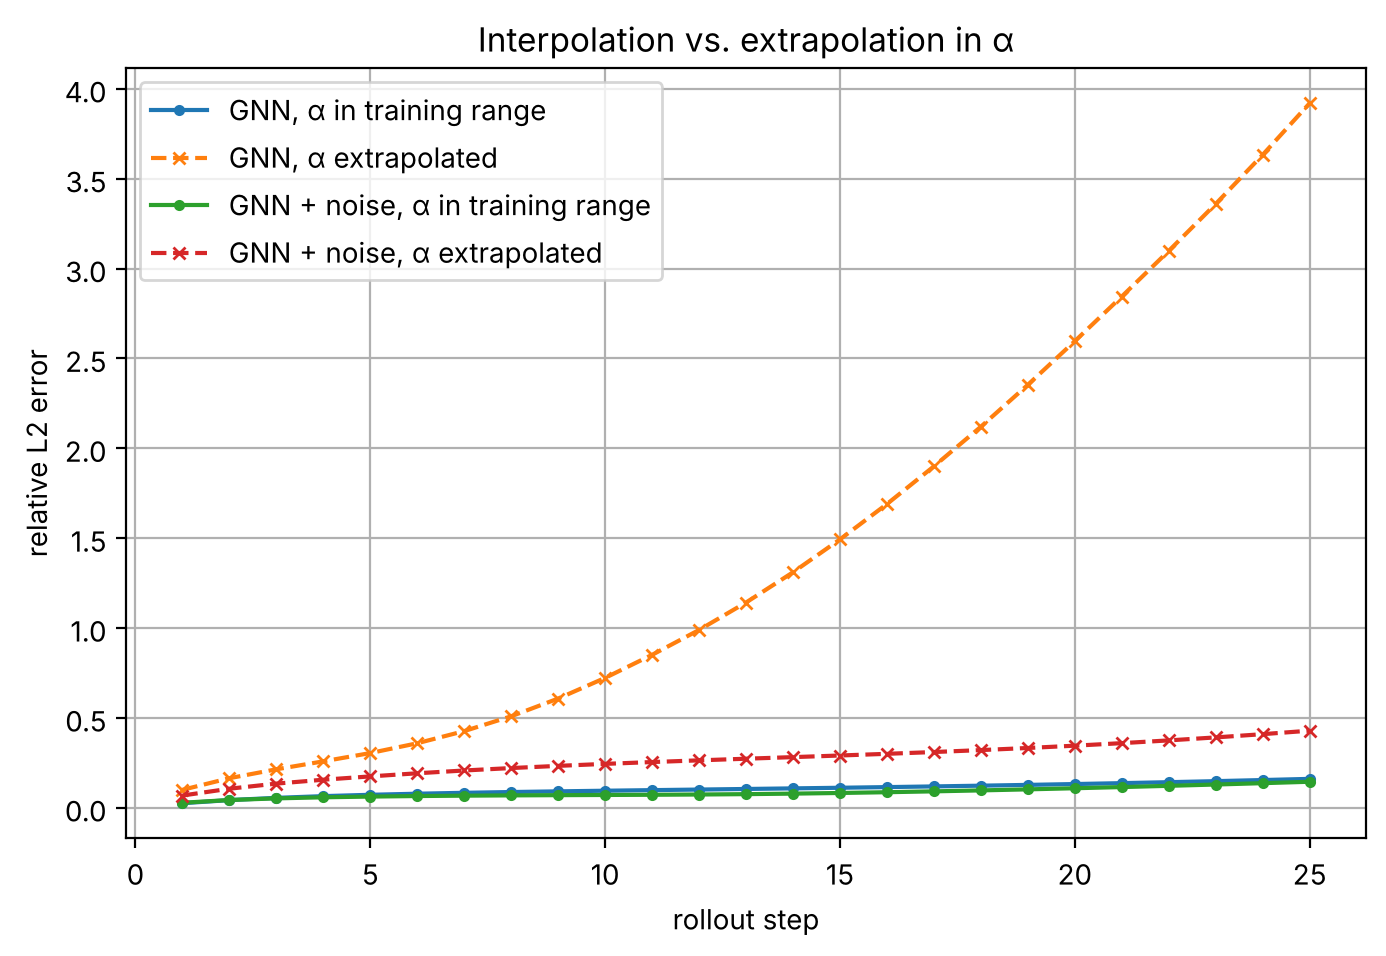

In [27]:
roll_extrap = {name: rollout_errors(m, extrap_trajs) for name, m in
               [("Persistence", Persistence()), ("MLP", mlp), ("GNN", model), ("GNN + noise", model_noise)]}

plt.figure(figsize=(8, 5))
for name in ["GNN", "GNN + noise"]:
    plt.plot(steps, roll[name], marker="o", markersize=3, label=f"{name}, α in training range")
    plt.plot(steps, roll_extrap[name], marker="x", markersize=4, linestyle="--", label=f"{name}, α extrapolated")
plt.xlabel("rollout step")
plt.ylabel("relative L2 error")
plt.title("Interpolation vs. extrapolation in α")
plt.legend()
plt.grid(True)
plt.show()

Outside the training range, both models get worse — but very differently. The plain GNN becomes **unstable**: its errors feed on themselves and the rollout runs away. The noise-trained GNN degrades but stays bounded, because it learned to pull slightly-wrong states back towards plausible ones.

Even the better model is clearly less accurate than inside the training range. This is the normal behaviour of a data-driven model, not a bug: a surrogate is only trustworthy inside the region its data covers. That is why the coverage plot in Section 9 matters.

## 26. A finer mesh

In [28]:
roll_fine = {name: rollout_errors(m, fine_trajs) for name, m in
             [("Persistence", Persistence()), ("MLP", mlp), ("GNN", model), ("GNN + noise", model_noise)]}

## 27. Summary table

In [29]:
print(f"{'Model':12s} | {'1-step (interp.)':>16s} | {'25-step (interp.)':>17s} | {'25-step (extrap.)':>17s} | {'25-step (n = 28)':>16s}")
print("-" * 92)
for name in ["Persistence", "MLP", "GNN", "GNN + noise"]:
    print(f"{name:12s} | {roll[name][0]:16.3f} | {roll[name][-1]:17.3f} | "
          f"{roll_extrap[name][-1]:17.3f} | {roll_fine[name][-1]:16.3f}")

Model        | 1-step (interp.) | 25-step (interp.) | 25-step (extrap.) | 25-step (n = 28)
--------------------------------------------------------------------------------------------
Persistence  |            0.127 |             2.288 |             6.268 |            2.581
MLP          |            0.078 |             0.560 |             1.234 |            0.882
GNN          |            0.026 |             0.161 |             3.920 |            0.828
GNN + noise  |            0.028 |             0.145 |             0.429 |            0.189


Two lessons stand out:

- **Noise training is what makes the surrogate robust.** On every shifted test — extrapolated $\alpha$ and the unseen finer mesh — the plain GNN's rollout degrades badly, while the noise-trained GNN stays close to its in-range accuracy on the finer mesh. Any distribution shift produces slightly unfamiliar inputs, and the noise-trained model has learned to handle them.
- **Time stepping eases the receptive-field problem from Tutorial 9.** In one step, heat travels only about $\sqrt{\alpha\Delta t}$ — a few mesh spacings (Exercise 1) — so a 4-layer GNN can see everything one step needs, even on a finer mesh. The global behaviour emerges from many local steps.

## 28. Is the surrogate worth it?

A surrogate is only useful if it is **cheaper** than the solver for the accuracy you need. Let's time both on a small and a large mesh.

In [30]:
def time_solver(n, alpha=0.03):
    t0 = time.perf_counter()
    tr = simulate(n, seed=0, alpha=alpha)
    return time.perf_counter() - t0, tr

def time_surrogate(m, tr):
    t0 = time.perf_counter()
    rollout(m, tr)
    return time.perf_counter() - t0

print(f"{'mesh':>9s} | {'nodes':>6s} | {'FEM solver (s)':>14s} | {'GNN rollout (s)':>15s}")
print("-" * 54)
for n in [20, 60, 120]:
    t_fem, tr = time_solver(n)
    t_gnn = time_surrogate(model_noise, tr)
    print(f"{n:4d}×{n:<4d} | {n * n:6d} | {t_fem:14.3f} | {t_gnn:15.3f}")

     mesh |  nodes | FEM solver (s) | GNN rollout (s)
------------------------------------------------------
  20×20   |    400 |          0.005 |           0.121


  60×60   |   3600 |          0.040 |           0.824


 120×120  |  14400 |          0.179 |           3.796


For this problem, the solver is **about 20–30 times faster** than the surrogate — even though the solver time also includes mesh generation and assembly. Linear heat conduction is cheap to solve: one sparse factorisation, then a back-substitution per step. A GNN with millions of multiply–adds per step does not beat that.

Surrogates pay off when the **solver is expensive** and the **same kind of problem is solved many times**:

- nonlinear, multiphysics, or turbulent flows where one simulation takes hours;
- design optimisation, uncertainty quantification, or control, where thousands of similar simulations are needed;
- real-time prediction, where the solver is too slow to run online.

Always compare against the solver you are replacing — on the hardware you will use.

# 🧪 Hands-on Exercise 2 — Physics-informed loss

Add the PDE residual to the training loss:

$$
\mathcal L=\frac{\text{MSE}(\hat{\mathbf T}^{n+1},\mathbf T^{n+1})}{\sigma_{\Delta T}^2}+\lambda\,\frac{\lVert\mathbf r(\hat{\mathbf T}^{n+1})\rVert^2}{\lVert\mathbf M\,\sigma_{\Delta T}\rVert^2}
$$

`pde_residual` already works on batches. Try $\lambda\in\{0.1, 1, 10\}$ and measure **all three** checks: rollout error, heat balance, and residual.

Does the residual go down? Does the rollout get better or worse? Do not assume that adding physics to the loss automatically improves every metric — measure it.

In [31]:
# TODO: physics-informed training.

# def fit_physics(model, lam, epochs=EPOCHS):
#     ...
#     pred = model(b)
#     loss = F.mse_loss(pred, b.y) / DT_STD**2 \
#          + lam * pde_residual(b, pred).pow(2).mean() / (b.m * DT_STD).pow(2).mean()

# 🧪 Hands-on Exercise 3 — Noise level

Train with `noise_std` in $\{0.003, 0.01, 0.03, 0.1\}$. Plot the rollout error after 25 steps against the noise level. Is there an optimum? What happens when the noise is much larger than a typical step $\sigma_{\Delta T}$?

In [32]:
# TODO: sweep the training-noise level.

# 🧪 Hands-on Exercise 4 — Ensemble uncertainty

Train 3–5 surrogates with different random seeds. Roll them all out on the same test plate and on an extrapolation plate.

1. Plot the ensemble mean and the spread (standard deviation) of the total heat $Q(t)$.
2. Is the spread larger for the extrapolation plate? Could the spread warn a user that a prediction is unreliable?

In [33]:
# TODO: build a small ensemble and compare its spread inside and outside the training range.

# 🧪 Hands-on Exercise 5 — A conservative message

In a finite-volume method, the flux from cell $j$ to cell $i$ is exactly the negative of the flux from $i$ to $j$. This **antisymmetry** guarantees that heat is only moved, never created.

Design a message function that is antisymmetric by construction, for example:

$$
\mathbf m_{j\rightarrow i}=\phi\left(\mathbf h_i,\mathbf h_j,\mathbf e_{ji}\right)-\phi\left(\mathbf h_j,\mathbf h_i,\mathbf e_{ij}\right)
$$

and use **sum** aggregation for the temperature update. Without boundaries, what does this guarantee for $\sum_i T_i$? How does the lumped mass $m_i$ enter?

In [34]:
# TODO: implement an antisymmetric (conservative) message-passing layer.

# Part IX — Trustworthy scientific ML

## 29. A checklist

| Question | How we checked it in this tutorial |
|---|---|
| Does it beat trivial baselines? | persistence and MLP (Parts IV–V) |
| Is it evaluated the way it will be used? | multi-step **rollout**, not just one step (Part V) |
| Are known constraints exact? | hard boundary condition (Section 22) |
| Are global quantities right? | total heat $Q(t)$ (Section 23) |
| Is the local physics consistent? | discrete PDE residual (Section 24) |
| Where does the data come from? | parameter coverage plot (Section 9) |
| Does it extrapolate? | $\alpha$ outside the training range (Section 25) |
| Does it transfer to new meshes? | unseen meshes and an unseen resolution (Section 26) |
| Is it worth it? | runtime vs. the solver (Section 28) |
| How uncertain is it? | ensembles (Exercise 4) |

## 30. Research directions

| Direction | Idea | Reference |
|---|---|---|
| Mesh-based simulators | encode–process–decode on meshes, noise injection, adaptive remeshing | Pfaff et al. (2021) |
| Particle simulators | GNNs for fluids and granular media as particle systems | Sanchez-Gonzalez et al. (2020) |
| Neural PDE solvers | message passing designed around PDE structure, rollout training | Brandstetter et al. (2022) |
| Multi-scale GNNs | coarse meshes for long-range information (Tutorial 9, Section 24) | Fortunato et al. (2022) |
| Geometric deep learning | symmetry and invariance as design principles | Bronstein et al. (2021) |
| Conservative / physics-constrained GNNs | antisymmetric fluxes, hard constraints, residual losses | Exercise 2, Exercise 5 |
| Software | production-grade SciML models and workflows | NVIDIA PhysicsNeMo |

# 🚀 Final Project — Your own graph surrogate

This is the capstone project of the series.

**Objective:** build a GNN surrogate for a physical system of your choice and evaluate it with the full checklist from Section 29.

**Project options:**

| Option | Problem | Prediction |
|---|---|---|
| A | Transient heat conduction with **heat sources** and **varying conductivity** | temperature rollout |
| B | CFD with OpenFOAM: flow past an obstacle for different inlet velocities | pressure and velocity fields |
| C | Global performance surrogate | pressure drop, drag, or heat-transfer rate (Tutorial 8 readout) |
| D | Structural mechanics: plates with holes under different loads | displacement and stress fields |

**Recommended workflow:**

1. Generate or export simulation cases; plot the **parameter coverage**.
2. Build one graph per case (and per time step), with geometric edge features (Tutorial 9).
3. Split **by case**; hold out a parameter region and a mesh resolution.
4. Train with residual learning and hard constraints; add noise for time-stepping models.
5. Compare against persistence, an MLP, and the solver.
6. Report field error, rollout error, global quantities, physical residuals, and runtime.

| Model | Field / rollout error | Extrapolation | Unseen mesh | Global quantity | Residual | Runtime vs. solver |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | ? | ? | ? | ? | ? | ? |
| GNN | ? | ? | ? | ? | ? | ? |
| GNN + your improvement | ? | ? | ? | ? | ? | ? |

**The central question:** can a graph neural network provide accurate, efficient, **and** physically trustworthy predictions for your system — and where exactly are its limits?

### Completion checklist

- [ ] I can explain the difference between one-shot and time-stepping surrogates.
- [ ] I built and verified a transient FEM solver as a data generator.
- [ ] I wrote the FEM operator as message passing and verified it against SciPy.
- [ ] I trained a step surrogate with residual learning and a hard boundary condition.
- [ ] I evaluated multi-step rollouts and compared them with persistence and an MLP.
- [ ] I used training noise to stabilise rollouts.
- [ ] I checked boundary values, total heat, and the PDE residual.
- [ ] I tested extrapolation, an unseen mesh resolution, and the runtime against the solver.

# 31. Summary of this tutorial

We learned:
- how a time-stepping surrogate differs from a one-shot surrogate, and why it suits local message passing
- how to generate trajectory data with an implicit-Euler finite-element solver, and verify it
- how to condition a GNN on an operating parameter, and why parameter coverage matters
- that residual learning and hard boundary conditions are simple, effective design choices
- that a finite-element operator is itself message passing with fixed weights
- that a small one-step error does not guarantee a stable rollout, and how training noise helps
- that field error, global balance, and local residual are different checks — and all are needed
- that surrogates degrade outside their training range, and are only worth it when the solver is expensive

# 32. Completing the series

| Stage | Tutorials | What you learned |
|---|---|---|
| Foundations | 1–3 | graphs, adjacency matrices, GCN from scratch, training with PyTorch |
| Tools | 4 | PyTorch Geometric, `Data`, `edge_index`, Cora |
| Inside the layer | 5–7 | message passing, attention, aggregators, sampling, inductive learning |
| Whole graphs | 8 | readouts, graph batching, classification and regression |
| Meshes | 9 | mesh → graph, geometric edge features, FEM data, mesh generalisation |
| Scientific ML | 10 | time-stepping surrogates, rollouts, physics checks, honest evaluation |

The thread through all ten tutorials:

> **Every GNN layer is message, aggregate, update.** Graphs, attention, sampling, readouts, meshes, and even a finite-element operator are all variations on that one idea. What makes a model *scientific* is not the layer — it is how carefully you test it against the physics.

---

## References and further reading

1. Pfaff, T. et al. (2021). [Learning Mesh-Based Simulation with Graph Networks](https://arxiv.org/abs/2010.03409). ICLR.
2. Sanchez-Gonzalez, A. et al. (2020). [Learning to Simulate Complex Physics with Graph Networks](https://arxiv.org/abs/2002.09405). ICML.
3. Brandstetter, J., Worrall, D., and Welling, M. (2022). [Message Passing Neural PDE Solvers](https://arxiv.org/abs/2202.03376). ICLR.
4. Fortunato, M. et al. (2022). [MultiScale MeshGraphNets](https://arxiv.org/abs/2210.00612). ICML AI4Science Workshop.
5. Bronstein, M. et al. (2021). [Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges](https://arxiv.org/abs/2104.13478).
6. Gilmer, J. et al. (2017). [Neural Message Passing for Quantum Chemistry](https://proceedings.mlr.press/v70/gilmer17a.html). ICML.

- [PyTorch Geometric](https://github.com/pyg-team/pytorch_geometric) · [`MessagePassing`](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.conv.MessagePassing.html)
- [DeepMind MeshGraphNets](https://github.com/google-deepmind/deepmind-research/tree/master/meshgraphnets) · [Learning to Simulate](https://github.com/google-deepmind/deepmind-research/tree/master/learning_to_simulate)
- [NVIDIA PhysicsNeMo](https://github.com/NVIDIA/physicsnemo)

---

**Learn the graph. Understand the message passing. Build the model. Connect it to the physical world.**

*HalfQubiX · The Learning Stack*

**You have completed the ten-part GNN series — from graph fundamentals to scientific machine learning. 🎓**